## UI heriachry in OOP 

In [ ]:
#As an AI engineer in geochemistry and remote sensing, your core value is building models (like SVMs or Clustering algorithms) and automating complex data pipelines. However, if those models 
only live in Jupyter Notebooks or terminal scripts, their impact is limited to people who know how to code

In [ ]:
QApplication (app)
    │
    └── QMainWindow (ElementalSocietyAnalysis)
            │
            ├── menu bar           ← NOT USED (you have custom toolbar instead)
            ├── toolbar            ← build_toolbar() – Upload, Clean, Filter buttons
            ├── central widget     ← central QWidget – holds everything
            │       │
            │       ├── QHBoxLayout (main_layout)
            │       │       │
            │       │       ├── sidebar (QWidget, fixed 230px)
            │       │       │     └── QVBoxLayout
            │       │       │          ├── Brand label
            │       │       │          ├── nav QListWidget
            │       │       │          ├── Help button
            │       │       │          └── Version label
            │       │       │
            │       │       └── right QWidget
            │       │             └── QVBoxLayout (r_layout)
            │       │                  ├── toolbar QWidget
            │       │                  │     └── QHBoxLayout
            │       │                  │          ├── Upload button
            │       │                  │          ├── Clean button
            │       │                  │          ├── Filter button
            │       │                  │          └── ... more buttons
            │       │                  │
            │       │                  ├── status_panel QWidget
            │       │                  │     └── QHBoxLayout
            │       │                  │          ├── status_lbl QLabel
            │       │                  │          └── progress QProgressBar
            │       │                  │
            │       │                  └── QStackedWidget (self.stack)
            │       │                        ├── Home page
            │       │                        ├── Dataset page
            │       │                        ├── Distributions page
            │       │                        ├── Analysis page
            │       │                        ├── Geochemistry page
            │       │                        ├── Clustering page
            │       │                        ├── SVM Classifier page
            │       │                        └── Logs page
            │       │
            └── status bar          ← NOT USED (you have custom status_panel)

In [ ]:
QMainWindow (ElementalSocietyAnalysis)
 └── Central Widget (QWidget)
      └── Main Layout (QHBoxLayout - Side-by-Side Split)
           ├── Left: Sidebar (Navigation Panel)
           └── Right: Main Container (QWidget with QVBoxLayout)
                ├── Top: Toolbar
                ├── Middle: QStackedWidget (Dynamic Pages / Content)
                └── Bottom: Custom Status Panel

In [ ]:
QMainWindow (self)                          ← the OS-level window itself
 └── central QWidget (setCentralWidget)      ← REQUIRED container; QMainWindow
      │                                        can't hold widgets directly
      └── QHBoxLayout (main_layout)          ← arranges children left-to-right
           ├── sidebar QWidget                ← fixed-width nav (230px)
           │    └── QVBoxLayout               ← brand label, nav list, help, version
           │
           └── right QWidget                  ← everything else
                └── QVBoxLayout (r_layout)     ← stacks top-to-bottom
                     ├── toolbar QWidget       ← Upload/Clean/Correction/etc buttons
                     ├── status_panel QWidget  ← "Ready - Upload a file..." bar
                     └── QStackedWidget (self.stack)
                          ├── page 0: Home
                          ├── page 1: Dataset
                          ├── page 2: Distributions
                          ├── page 3: Analysis
                          ├── page 4: Geochemistry
                          ├── page 5: Clustering
                          ├── page 6: SVM Classifier
                          ├── page 7: Workflow
                          └── page 8: Logs

In [ ]:
#1. how to inherite the behavorirs of qmainwindows to our class 

class elementalsociety(Qmainwindow):
    def __init__(self):
        super().__init__()

#the behavorirs of qmainwindows
setWindowTitle()
setGeometry()
setCentralWidget()
show()
menuBar()
statusBar()
addToolBar()  

In [ ]:
class dataingapp(QmainWindow):
    def __init__(self):
        super().__init__()
# for the structure for tools : 
central = Qwidget()
layout = QVBoxLayout(central)
self.setCentralWidget(central)



In [1]:
import numpy as np
import pandas as pd
from scipy.stats import gmean

class CompositionalData:
    """
    A class that handles closed geochemical data.
    Like a lab protocol that knows how to handle samples
    that must sum to 100%.
    """
    
    def __init__(self, data, oxide_columns):
        """
        data: pandas DataFrame with your samples
        oxide_columns: list of column names that are oxides
        
        self = "THIS specific dataset in my hand right now"
        """
        self._raw_data = data.copy()           # Encapsulated – don't touch directly
        self.oxide_columns = oxide_columns
        self._clr_data = None                  # Will store CLR-transformed data
        
        # Check closure immediately
        self._check_closure()
    
    def _check_closure(self):
        """PRIVATE method – internal use only"""
        oxide_sums = self._raw_data[self.oxide_columns].sum(axis=1)
        self.cv = oxide_sums.std() / oxide_sums.mean()
        
        if self.cv < 0.10:
            self.is_closed = True
            print(f"⚠️  Data is CLOSED (CV={self.cv:.3f})")
            print("   Spurious correlations WILL be present!")
        else:
            self.is_closed = False
            print(f"✅ Data is NOT closed (CV={self.cv:.3f})")
    
    @property
    def raw_correlations(self):
        """Get correlations from raw (biased) data"""
        return self._raw_data[self.oxide_columns].corr()
    
    @property
    def clr_correlations(self):
        """Get correlations from CLR (corrected) data"""
        if self._clr_data is None:
            self.apply_clr()  # Auto-apply if not done yet
        return self._clr_data.corr()
    
    def apply_clr(self):
        """
        Apply CLR transformation to fix closure.
        Like a lab procedure that corrects for instrument drift.
        """
        # Make a copy and handle zeros
        data = self._raw_data[self.oxide_columns].copy()
        data = data.replace(0, 1e-10)
        
        # Geometric mean of each row
        gm = gmean(data, axis=1).reshape(-1, 1)
        
        # CLR: log of ratio to geometric mean
        clr_values = np.log(data.values / gm)
        
        self._clr_data = pd.DataFrame(
            clr_values, 
            columns=self.oxide_columns,
            index=self._raw_data.index
        )
        
        print(f"✅ CLR transformation applied to {len(self.oxide_columns)} oxides")
        return self._clr_data
    
    def compare_correlations(self, oxide1, oxide2):
        """Compare raw vs CLR correlation for a specific pair"""
        raw_r = self._raw_data[oxide1].corr(self._raw_data[oxide2])
        
        if self._clr_data is None:
            self.apply_clr()
        clr_r = self._clr_data[oxide1].corr(self._clr_data[oxide2])
        
        bias = raw_r - clr_r
        
        print(f"\n📊 {oxide1} vs {oxide2}:")
        print(f"   Raw (biased):   r = {raw_r:+.3f}")
        print(f"   CLR (correct):  r = {clr_r:+.3f}")
        print(f"   Closure bias:   {bias:+.3f}")
        
        if abs(bias) > 0.2:
            print(f"   ⚠️  STRONG closure effect – use CLR values!")
        
        return raw_r, clr_r, bias

ImportError: DLL load failed while importing _propack: The specified module could not be found.

In [5]:
import numpy as np
import pandas as pd

class CompositionalData:
    """
    A class that handles closed geochemical data.
    """
    
    def __init__(self, data, oxide_columns):
        self._raw_data = data.copy()
        self.oxide_columns = oxide_columns
        self._clr_data = None
        self._check_closure()
    
    def _check_closure(self):
        """PRIVATE method – internal use only"""
        oxide_sums = self._raw_data[self.oxide_columns].sum(axis=1)
        self.cv = oxide_sums.std() / oxide_sums.mean()
        
        if self.cv < 0.10:
            self.is_closed = True
            print(f"⚠️  Data is CLOSED (CV={self.cv:.3f})")
            print("   Spurious correlations WILL be present!")
        else:
            self.is_closed = False
            print(f"✅ Data is NOT closed (CV={self.cv:.3f})")
    
    @property
    def raw_correlations(self):
        """Get correlations from raw (biased) data"""
        return self._raw_data[self.oxide_columns].corr()
    
    @property
    def clr_correlations(self):
        """Get correlations from CLR (corrected) data"""
        if self._clr_data is None:
            self.apply_clr()
        return self._clr_data.corr()
    
    def apply_clr(self):
        """
        Apply CLR transformation using ONLY NumPy (no SciPy needed).
        """
        # Make a copy and handle zeros
        data = self._raw_data[self.oxide_columns].copy()
        data = data.replace(0, 1e-10)
        
        # Geometric mean using NumPy (no SciPy required!)
        # gmean = (x1 * x2 * ... * xn)^(1/n) = exp(mean(log(x)))
        log_data = np.log(data.values)
        gm = np.exp(log_data.mean(axis=1)).reshape(-1, 1)
        
        # CLR: log of ratio to geometric mean
        clr_values = log_data - np.log(gm)
        
        self._clr_data = pd.DataFrame(
            clr_values, 
            columns=self.oxide_columns,
            index=self._raw_data.index
        )
        
        print(f"✅ CLR transformation applied to {len(self.oxide_columns)} oxides")
        return self._clr_data
    
    def compare_correlations(self, oxide1, oxide2):
        """Compare raw vs CLR correlation for a specific pair"""
        raw_r = self._raw_data[oxide1].corr(self._raw_data[oxide2])
        
        if self._clr_data is None:
            self.apply_clr()
        clr_r = self._clr_data[oxide1].corr(self._clr_data[oxide2])
        
        bias = raw_r - clr_r
        
        print(f"\n📊 {oxide1} vs {oxide2}:")
        print(f"   Raw (biased):   r = {raw_r:+.3f}")
        print(f"   CLR (correct):  r = {clr_r:+.3f}")
        print(f"   Closure bias:   {bias:+.3f}")
        
        if abs(bias) > 0.2:
            print(f"   ⚠️  STRONG closure effect – use CLR values!")
        
        return raw_r, clr_r, bias


# ============================================================
# TEST WITH YOUR DATA
# ============================================================

# Load your data
df = pd.read_excel('Major elements all.xlsx')

# Define oxide columns
oxides = ['SiO2', 'Al2O3', 'MgO', 'CaO', 'Na2O', 'K2O', 'Fe2O3', 'MnO', 'TiO2']

# Create CompositionalData object
my_data = CompositionalData(df, oxides)

# Apply CLR
my_data.apply_clr()

# Compare
my_data.compare_correlations('SiO2', 'Al2O3')
my_data.compare_correlations('SiO2', 'MgO')

⚠️  Data is CLOSED (CV=0.062)
   Spurious correlations WILL be present!
✅ CLR transformation applied to 9 oxides

📊 SiO2 vs Al2O3:
   Raw (biased):   r = -0.797
   CLR (correct):  r = -0.296
   Closure bias:   -0.501
   ⚠️  STRONG closure effect – use CLR values!

📊 SiO2 vs MgO:
   Raw (biased):   r = -0.603
   CLR (correct):  r = +0.047
   Closure bias:   -0.651
   ⚠️  STRONG closure effect – use CLR values!


(-0.603391389837579, 0.047118589455154784, -0.6505099792927338)

In [11]:
print(f'{my_data}')

In [15]:
import numpy as np
import pandas as pd


class CompositionalData:
    """
    Handles closed geochemical data: detects closure, applies the
    centered log-ratio (CLR) transform, and compares raw vs. CLR
    correlations to quantify closure-induced bias.
    """

    def __init__(self, data, oxide_columns):
        missing = [c for c in oxide_columns if c not in data.columns]
        if missing:
            raise ValueError(f"Missing oxide columns in data: {missing}")

        self._raw_data = data.copy()
        self._oxide_columns = list(oxide_columns)   # protect the list itself
        self._clr_data = None
        self._cv = None
        self._is_closed = None
        self._check_closure()

    @property
    def oxide_columns(self):
        return list(self._oxide_columns)   # return a copy, not the live list

    @property
    def cv(self):
        return self._cv

    @property
    def is_closed(self):
        return self._is_closed

    def _check_closure(self):
        """Internal: computes closure diagnostics at construction time."""
        oxide_sums = self._raw_data[self._oxide_columns].sum(axis=1)
        self._cv = oxide_sums.std() / oxide_sums.mean()
        self._is_closed = self._cv < 0.10

        status = "⚠️  CLOSED" if self._is_closed else "✅ NOT closed"
        print(f"{status} (CV={self._cv:.3f})")
        if self._is_closed:
            print("   Spurious correlations WILL be present — use CLR results.")

    @property
    def raw_correlations(self):
        """Correlations from raw (closure-biased) data."""
        return self._raw_data[self._oxide_columns].corr()

    @property
    def clr_correlations(self):
        """Correlations from CLR-corrected data (computed lazily, cached)."""
        return self.apply_clr().corr()

    def apply_clr(self, force: bool = False):
        """
        Apply the centered log-ratio transform. Cached after first call;
        pass force=True to recompute (e.g. after correcting raw_data).
        """
        if self._clr_data is not None and not force:
            return self._clr_data

        data = self._raw_data[self._oxide_columns].copy()
        if (data < 0).any().any():
            raise ValueError("Negative oxide values found — check raw data.")
        data = data.replace(0, 1e-10)   # log(0) guard

        log_data = np.log(data.values)
        gm = np.exp(log_data.mean(axis=1)).reshape(-1, 1)
        clr_values = log_data - np.log(gm)

        self._clr_data = pd.DataFrame(
            clr_values, columns=self._oxide_columns, index=self._raw_data.index
        )
        print(f"✅ CLR transformation applied to {len(self._oxide_columns)} oxides")
        return self._clr_data

    def compare_correlations(self, oxide1, oxide2, bias_threshold: float = 0.2):
        """Compare raw vs. CLR correlation for one oxide pair."""
        raw_r = self._raw_data[oxide1].corr(self._raw_data[oxide2])
        clr_r = self.apply_clr()[oxide1].corr(self.apply_clr()[oxide2])
        bias = raw_r - clr_r

        print(f"\n📊 {oxide1} vs {oxide2}:")
        print(f"   Raw (biased):   r = {raw_r:+.3f}")
        print(f"   CLR (correct):  r = {clr_r:+.3f}")
        print(f"   Closure bias:   {bias:+.3f}")
        if abs(bias) > bias_threshold:
            print("   ⚠️  STRONG closure effect – use CLR values!")

        return raw_r, clr_r, bias


# ============================================================
# USAGE
# ============================================================
df = pd.read_excel('Major elements all.xlsx')
oxides = ['SiO2', 'Al2O3', 'MgO', 'CaO', 'Na2O', 'K2O', 'Fe2O3', 'MnO', 'TiO2']

my_data = CompositionalData(df, oxides)
my_data.apply_clr()
my_data.compare_correlations('SiO2', 'Al2O3')
my_data.compare_correlations('SiO2', 'MgO')

⚠️  CLOSED (CV=0.062)
   Spurious correlations WILL be present — use CLR results.
✅ CLR transformation applied to 9 oxides

📊 SiO2 vs Al2O3:
   Raw (biased):   r = -0.797
   CLR (correct):  r = -0.296
   Closure bias:   -0.501
   ⚠️  STRONG closure effect – use CLR values!

📊 SiO2 vs MgO:
   Raw (biased):   r = -0.603
   CLR (correct):  r = +0.047
   Closure bias:   -0.651
   ⚠️  STRONG closure effect – use CLR values!


(-0.603391389837579, 0.047118589455154784, -0.6505099792927338)

⚠️  CLOSED (CV=0.062)
   Spurious correlations WILL be present — use CLR results.

FIGURE 1: Why Your Data Is Closed and Why It Matters
✅ CLR transformation applied to 9 oxides


C:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


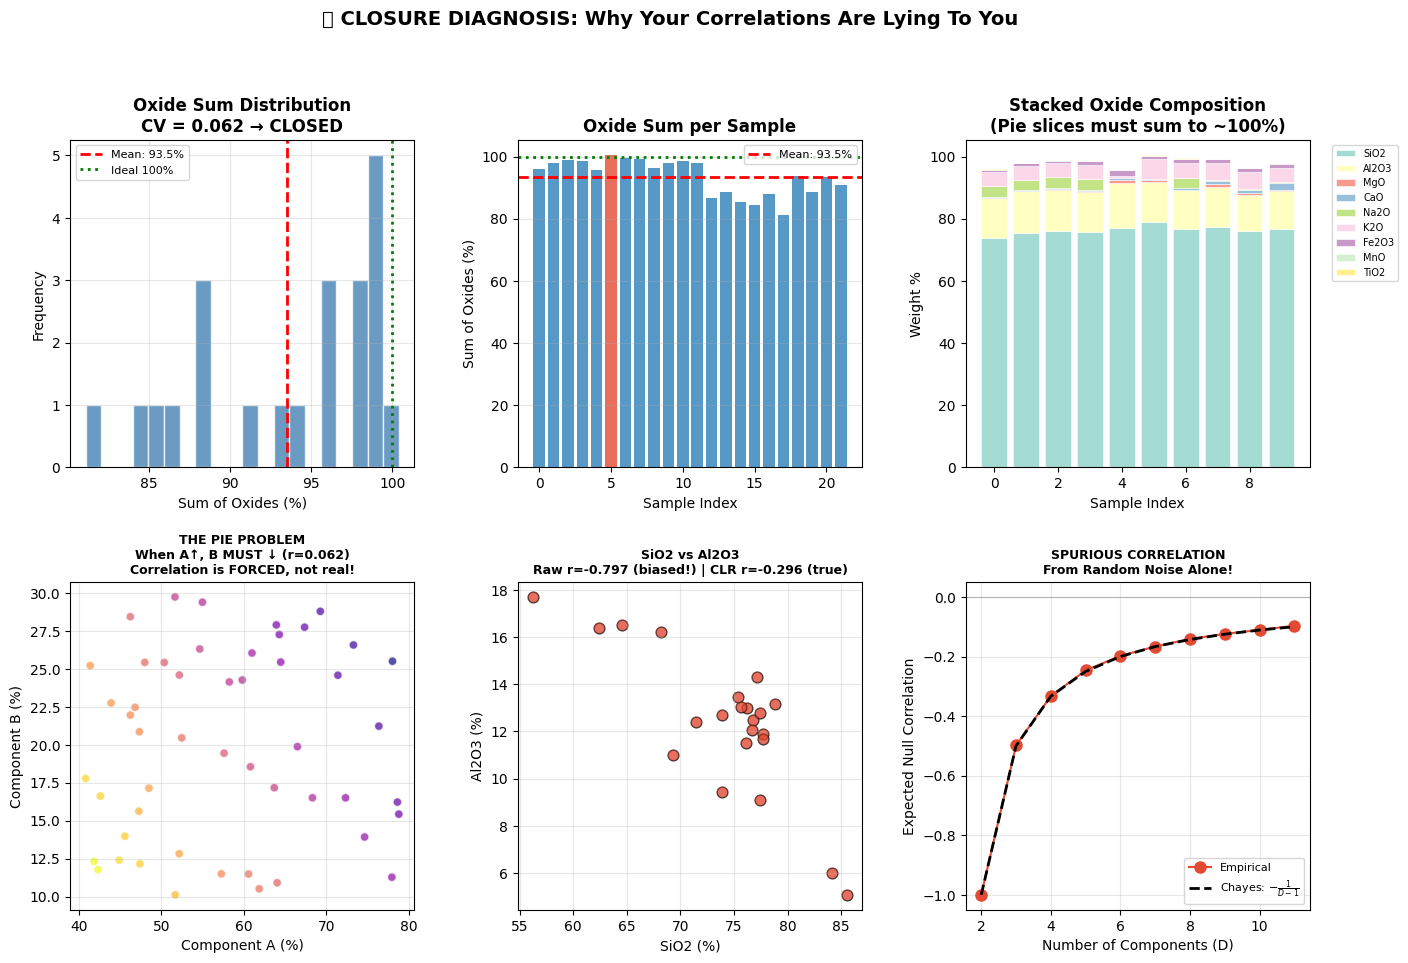


FIGURE 2: CLR Solution - Before vs After


C:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129514 (\N{TEST TUBE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


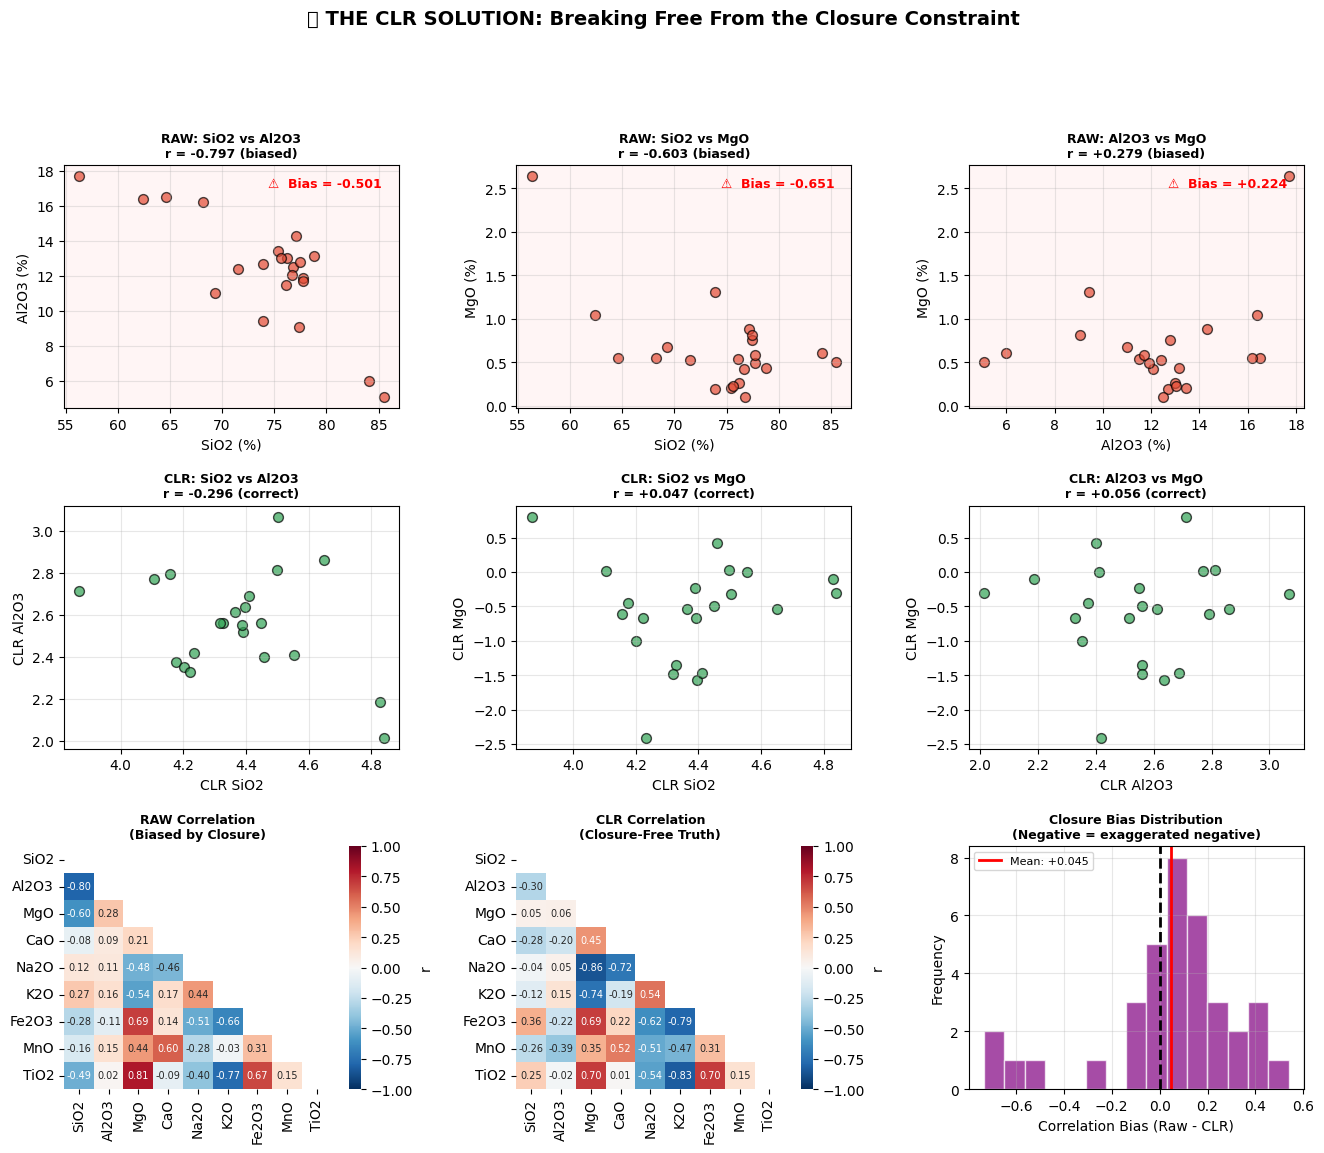


FIGURE 3: The Math Behind CLR (Step by Step)


C:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


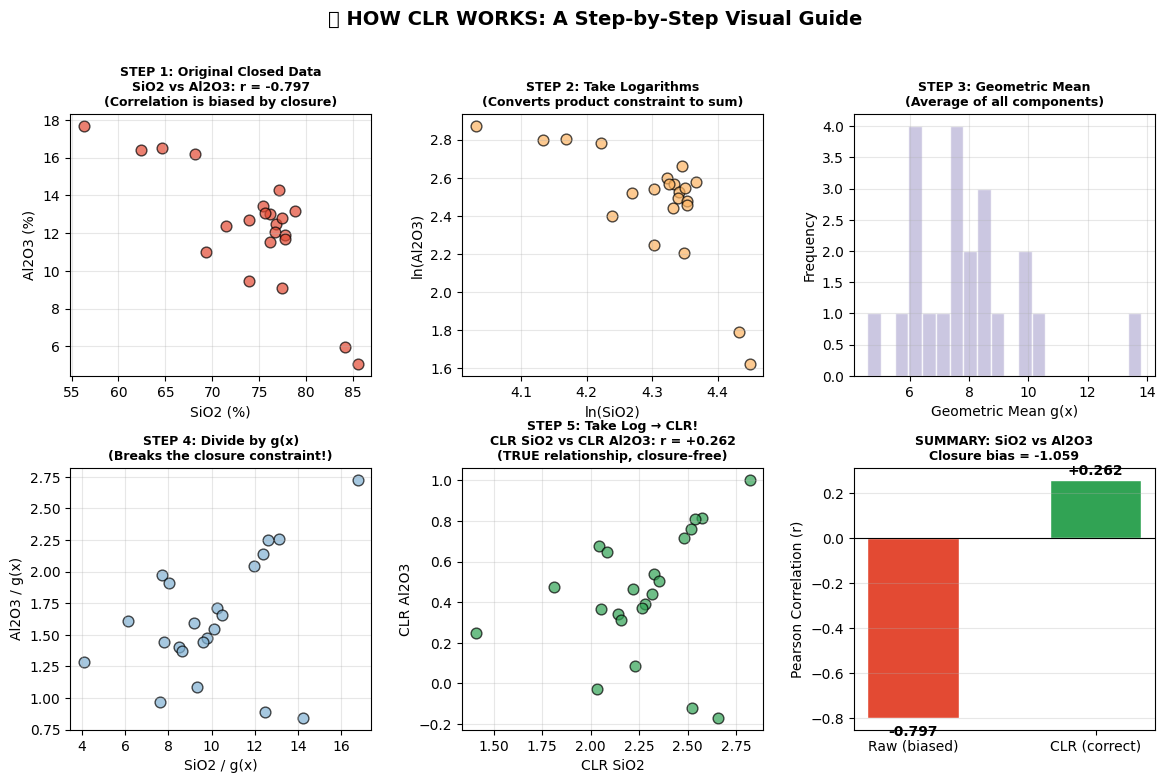

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

# Set style
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.size'] = 10

class CompositionalData:
    """
    Handles closed geochemical data with full visualization capabilities.
    """
    
    def __init__(self, data, oxide_columns):
        missing = [c for c in oxide_columns if c not in data.columns]
        if missing:
            raise ValueError(f"Missing oxide columns in data: {missing}")

        self._raw_data = data.copy()
        self._oxide_columns = list(oxide_columns)
        self._clr_data = None
        self._cv = None
        self._is_closed = None
        self._check_closure()
    
    @property
    def oxide_columns(self):
        return list(self._oxide_columns)
    
    @property
    def cv(self):
        return self._cv
    
    @property
    def is_closed(self):
        return self._is_closed
    
    def _check_closure(self):
        oxide_sums = self._raw_data[self._oxide_columns].sum(axis=1)
        self._cv = oxide_sums.std() / oxide_sums.mean()
        self._is_closed = self._cv < 0.10
        
        status = "⚠️  CLOSED" if self._is_closed else "✅ NOT closed"
        print(f"{status} (CV={self._cv:.3f})")
        if self._is_closed:
            print("   Spurious correlations WILL be present — use CLR results.")
    
    @property
    def raw_correlations(self):
        return self._raw_data[self._oxide_columns].corr()
    
    @property
    def clr_correlations(self):
        return self.apply_clr().corr()
    
    def apply_clr(self, force=False):
        if self._clr_data is not None and not force:
            return self._clr_data
        
        data = self._raw_data[self._oxide_columns].copy()
        if (data < 0).any().any():
            raise ValueError("Negative oxide values found — check raw data.")
        data = data.replace(0, 1e-10)
        
        log_data = np.log(data.values)
        gm = np.exp(log_data.mean(axis=1)).reshape(-1, 1)
        clr_values = log_data - np.log(gm)
        
        self._clr_data = pd.DataFrame(
            clr_values, columns=self._oxide_columns, index=self._raw_data.index
        )
        print(f"✅ CLR transformation applied to {len(self._oxide_columns)} oxides")
        return self._clr_data
    
    # ============================================================
    # VISUALIZATION METHODS
    # ============================================================
    
    def visualize_closure_diagnosis(self, figsize=(16, 10)):
        """
        FIGURE 1: Show that the data IS closed and why it matters.
        """
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)
        
        # (a) Histogram of oxide sums
        ax1 = fig.add_subplot(gs[0, 0])
        oxide_sums = self._raw_data[self._oxide_columns].sum(axis=1)
        ax1.hist(oxide_sums, bins=min(20, len(oxide_sums)), 
                color='steelblue', edgecolor='white', alpha=0.8)
        ax1.axvline(oxide_sums.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {oxide_sums.mean():.1f}%')
        ax1.axvline(100, color='green', linestyle=':', linewidth=2, label='Ideal 100%')
        ax1.set_xlabel('Sum of Oxides (%)')
        ax1.set_ylabel('Frequency')
        ax1.set_title(f'Oxide Sum Distribution\nCV = {self._cv:.3f} → {"CLOSED" if self._is_closed else "OPEN"}',
                     fontweight='bold')
        ax1.legend(fontsize=8)
        ax1.grid(True, alpha=0.3)
        
        # (b) Bar chart - oxide sum per sample
        ax2 = fig.add_subplot(gs[0, 1])
        colors = ['#e34a33' if s > 100 else '#2c7fb8' for s in oxide_sums]
        ax2.bar(range(len(oxide_sums)), oxide_sums, color=colors, alpha=0.8)
        ax2.axhline(oxide_sums.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {oxide_sums.mean():.1f}%')
        ax2.axhline(100, color='green', linestyle=':', linewidth=2)
        ax2.set_xlabel('Sample Index')
        ax2.set_ylabel('Sum of Oxides (%)')
        ax2.set_title('Oxide Sum per Sample', fontweight='bold')
        ax2.legend(fontsize=8)
        ax2.grid(True, alpha=0.3, axis='y')
        
        # (c) Stacked bar - composition of first 10 samples
        ax3 = fig.add_subplot(gs[0, 2])
        n_show = min(10, len(self._raw_data))
        top_oxides = self._raw_data[self._oxide_columns].iloc[:n_show]
        bottom = np.zeros(n_show)
        colors_stack = plt.cm.Set3(np.linspace(0, 1, len(self._oxide_columns)))
        
        for i, col in enumerate(self._oxide_columns):
            ax3.bar(range(n_show), top_oxides[col], bottom=bottom,
                   color=colors_stack[i], alpha=0.8, label=col, edgecolor='white', linewidth=0.5)
            bottom += top_oxides[col].values
        
        ax3.set_xlabel('Sample Index')
        ax3.set_ylabel('Weight %')
        ax3.set_title('Stacked Oxide Composition\n(Pie slices must sum to ~100%)', fontweight='bold')
        ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)
        
        # (d) THE PIE ANALOGY - Visual proof of closure
        ax4 = fig.add_subplot(gs[1, 0])
        # Create a simple 3-component demonstration
        np.random.seed(42)
        demo_a = np.random.uniform(40, 80, 50)
        demo_b = np.random.uniform(10, 30, 50)
        demo_c = 100 - demo_a - demo_b  # FORCED by closure!
        
        ax4.scatter(demo_a, demo_b, c=demo_c, cmap='plasma', s=40, alpha=0.7, edgecolors='white')
        ax4.set_xlabel('Component A (%)')
        ax4.set_ylabel('Component B (%)')
        r_demo = np.corrcoef(demo_a, demo_b)[0, 1]
        ax4.set_title(f'THE PIE PROBLEM\nWhen A↑, B MUST ↓ (r={r_demo:.3f})\nCorrelation is FORCED, not real!',
                     fontweight='bold', fontsize=9)
        ax4.grid(True, alpha=0.3)
        
        # (e) Raw vs CLR scatter for a key pair
        ax5 = fig.add_subplot(gs[1, 1])
        ox1, ox2 = self._oxide_columns[0], self._oxide_columns[1]
        raw_r = self._raw_data[ox1].corr(self._raw_data[ox2])
        clr_r = self.apply_clr()[ox1].corr(self.apply_clr()[ox2])
        
        ax5.scatter(self._raw_data[ox1], self._raw_data[ox2], 
                   s=60, alpha=0.7, edgecolors='k', color='#e34a33', label=f'Raw (r={raw_r:+.3f})')
        ax5.scatter(self._raw_data[ox1], self._raw_data[ox2], 
                   s=60, alpha=0.3, edgecolors='none', color='#e34a33')
        ax5.set_xlabel(f'{ox1} (%)')
        ax5.set_ylabel(f'{ox2} (%)')
        ax5.set_title(f'{ox1} vs {ox2}\nRaw r={raw_r:+.3f} (biased!) | CLR r={clr_r:+.3f} (true)',
                     fontweight='bold', fontsize=9)
        ax5.grid(True, alpha=0.3)
        
        # (f) Null model - Chayes effect
        ax6 = fig.add_subplot(gs[1, 2])
        D_range = np.arange(2, 12)
        empirical_r = []
        for D in D_range:
            r_vals = []
            for _ in range(200):
                raw = np.random.exponential(1, (500, D))
                closed = raw / raw.sum(axis=1, keepdims=True)
                r_vals.append(np.corrcoef(closed[:, 0], closed[:, 1])[0, 1])
            empirical_r.append(np.mean(r_vals))
        
        theoretical_r = [-1/(D-1) for D in D_range]
        ax6.plot(D_range, empirical_r, 'o-', color='#e34a33', label='Empirical', markersize=8)
        ax6.plot(D_range, theoretical_r, '--', color='black', linewidth=2, 
                label=r'Chayes: $-\frac{1}{D-1}$')
        ax6.axhline(0, color='gray', lw=0.8, alpha=0.5)
        ax6.set_xlabel('Number of Components (D)')
        ax6.set_ylabel('Expected Null Correlation')
        ax6.set_title('SPURIOUS CORRELATION\nFrom Random Noise Alone!', fontweight='bold', fontsize=9)
        ax6.legend(fontsize=8)
        ax6.grid(True, alpha=0.3)
        
        fig.suptitle('🔍 CLOSURE DIAGNOSIS: Why Your Correlations Are Lying To You',
                    fontsize=14, fontweight='bold', y=1.01)
        plt.show()
    
    def visualize_clr_solution(self, figsize=(16, 12)):
        """
        FIGURE 2: Show how CLR transformation fixes the problem.
        """
        # Apply CLR
        clr_data = self.apply_clr()
        
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(3, 3, figure=fig, hspace=0.4, wspace=0.35)
        
        # Row 1: Raw vs CLR scatter for 3 key pairs
        key_pairs = [
            (self._oxide_columns[0], self._oxide_columns[1]),
            (self._oxide_columns[0], self._oxide_columns[2]),
            (self._oxide_columns[1], self._oxide_columns[2]),
        ]
        
        for i, (ox1, ox2) in enumerate(key_pairs):
            # Raw
            ax = fig.add_subplot(gs[0, i])
            raw_r = self._raw_data[ox1].corr(self._raw_data[ox2])
            clr_r = clr_data[ox1].corr(clr_data[ox2])
            bias = raw_r - clr_r
            
            ax.scatter(self._raw_data[ox1], self._raw_data[ox2], 
                      s=50, alpha=0.7, edgecolors='k', color='#e34a33')
            ax.set_xlabel(f'{ox1} (%)')
            ax.set_ylabel(f'{ox2} (%)')
            ax.set_title(f'RAW: {ox1} vs {ox2}\nr = {raw_r:+.3f} (biased)', fontweight='bold', fontsize=9)
            ax.grid(True, alpha=0.3)
            
            if abs(bias) > 0.15:
                ax.set_facecolor('#fff5f5')
                ax.text(0.95, 0.95, f'⚠️  Bias = {bias:+.3f}', transform=ax.transAxes,
                       ha='right', va='top', fontsize=9, color='red', fontweight='bold')
        
        # Row 2: CLR-transformed scatter for same pairs
        for i, (ox1, ox2) in enumerate(key_pairs):
            ax = fig.add_subplot(gs[1, i])
            raw_r = self._raw_data[ox1].corr(self._raw_data[ox2])
            clr_r = clr_data[ox1].corr(clr_data[ox2])
            bias = raw_r - clr_r
            
            ax.scatter(clr_data[ox1], clr_data[ox2], 
                      s=50, alpha=0.7, edgecolors='k', color='#31a354')
            ax.set_xlabel(f'CLR {ox1}')
            ax.set_ylabel(f'CLR {ox2}')
            ax.set_title(f'CLR: {ox1} vs {ox2}\nr = {clr_r:+.3f} (correct)', fontweight='bold', fontsize=9)
            ax.grid(True, alpha=0.3)
            
            if abs(bias) < 0.10:
                ax.set_facecolor('#f5fff5')
                ax.text(0.95, 0.95, f'✅ Recovered!', transform=ax.transAxes,
                       ha='right', va='top', fontsize=9, color='green', fontweight='bold')
        
        # Row 3: Correlation matrices and bias distribution
        # (g) Raw correlation heatmap
        ax7 = fig.add_subplot(gs[2, 0])
        raw_corr = self.raw_correlations
        mask = np.triu(np.ones_like(raw_corr, dtype=bool))
        sns.heatmap(raw_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                   vmin=-1, vmax=1, mask=mask, ax=ax7, cbar_kws={'label': 'r'},
                   annot_kws={'size': 7})
        ax7.set_title('RAW Correlation\n(Biased by Closure)', fontweight='bold', fontsize=9)
        
        # (h) CLR correlation heatmap
        ax8 = fig.add_subplot(gs[2, 1])
        clr_corr = self.clr_correlations
        sns.heatmap(clr_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                   vmin=-1, vmax=1, mask=mask, ax=ax8, cbar_kws={'label': 'r'},
                   annot_kws={'size': 7})
        ax8.set_title('CLR Correlation\n(Closure-Free Truth)', fontweight='bold', fontsize=9)
        
        # (i) Bias distribution
        ax9 = fig.add_subplot(gs[2, 2])
        biases = []
        for i in range(len(self._oxide_columns)):
            for j in range(i+1, len(self._oxide_columns)):
                biases.append(raw_corr.iloc[i, j] - clr_corr.iloc[i, j])
        
        ax9.hist(biases, bins=15, color='purple', alpha=0.7, edgecolor='white')
        ax9.axvline(0, color='black', linestyle='--', linewidth=2)
        ax9.axvline(np.mean(biases), color='red', linestyle='-', linewidth=2,
                   label=f'Mean: {np.mean(biases):+.3f}')
        ax9.set_xlabel('Correlation Bias (Raw - CLR)')
        ax9.set_ylabel('Frequency')
        ax9.set_title('Closure Bias Distribution\n(Negative = exaggerated negative)', fontweight='bold', fontsize=9)
        ax9.legend(fontsize=8)
        ax9.grid(True, alpha=0.3)
        
        fig.suptitle('🧪 THE CLR SOLUTION: Breaking Free From the Closure Constraint',
                    fontsize=14, fontweight='bold', y=1.01)
        plt.show()
    
    def visualize_why_clr_works(self, figsize=(14, 8)):
        """
        FIGURE 3: Step-by-step explanation of WHY CLR works.
        """
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)
        
        # Use first 3 oxides for simplicity
        ox = self._oxide_columns[:3]
        data_3 = self._raw_data[ox].copy()
        data_3 = data_3.replace(0, 1e-10)
        
        # (a) Original data on simplex (3D-like via 2D)
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.scatter(data_3[ox[0]], data_3[ox[1]], s=60, alpha=0.7, 
                   edgecolors='k', color='#e34a33')
        ax1.set_xlabel(f'{ox[0]} (%)')
        ax1.set_ylabel(f'{ox[1]} (%)')
        r_orig = data_3[ox[0]].corr(data_3[ox[1]])
        ax1.set_title(f'STEP 1: Original Closed Data\n{ox[0]} vs {ox[1]}: r = {r_orig:+.3f}\n'
                     '(Correlation is biased by closure)',
                     fontweight='bold', fontsize=9)
        ax1.grid(True, alpha=0.3)
        
        # (b) Take logarithms
        ax2 = fig.add_subplot(gs[0, 1])
        log_data = np.log(data_3.values)
        ax2.scatter(log_data[:, 0], log_data[:, 1], s=60, alpha=0.7,
                   edgecolors='k', color='#fdb462')
        ax2.set_xlabel(f'ln({ox[0]})')
        ax2.set_ylabel(f'ln({ox[1]})')
        ax2.set_title('STEP 2: Take Logarithms\n(Converts product constraint to sum)',
                     fontweight='bold', fontsize=9)
        ax2.grid(True, alpha=0.3)
        
        # (c) Calculate geometric mean
        ax3 = fig.add_subplot(gs[0, 2])
        gm = np.exp(log_data.mean(axis=1))
        ax3.hist(gm, bins=20, color='#bebada', edgecolor='white', alpha=0.8)
        ax3.set_xlabel('Geometric Mean g(x)')
        ax3.set_ylabel('Frequency')
        ax3.set_title('STEP 3: Geometric Mean\n(Average of all components)',
                     fontweight='bold', fontsize=9)
        ax3.grid(True, alpha=0.3)
        
        # (d) Divide by geometric mean
        ax4 = fig.add_subplot(gs[1, 0])
        ratios = data_3.values / gm.reshape(-1, 1)
        ax4.scatter(ratios[:, 0], ratios[:, 1], s=60, alpha=0.7,
                   edgecolors='k', color='#80b1d3')
        ax4.set_xlabel(f'{ox[0]} / g(x)')
        ax4.set_ylabel(f'{ox[1]} / g(x)')
        ax4.set_title('STEP 4: Divide by g(x)\n(Breaks the closure constraint!)',
                     fontweight='bold', fontsize=9)
        ax4.grid(True, alpha=0.3)
        
        # (e) Take log of ratios (= CLR!)
        ax5 = fig.add_subplot(gs[1, 1])
        clr_vals = np.log(ratios)
        ax5.scatter(clr_vals[:, 0], clr_vals[:, 1], s=60, alpha=0.7,
                   edgecolors='k', color='#31a354')
        ax5.set_xlabel(f'CLR {ox[0]}')
        ax5.set_ylabel(f'CLR {ox[1]}')
        r_clr = np.corrcoef(clr_vals[:, 0], clr_vals[:, 1])[0, 1]
        ax5.set_title(f'STEP 5: Take Log → CLR!\nCLR {ox[0]} vs CLR {ox[1]}: r = {r_clr:+.3f}\n'
                     '(TRUE relationship, closure-free)',
                     fontweight='bold', fontsize=9)
        ax5.grid(True, alpha=0.3)
        
        # (f) Summary - Raw vs CLR side by side
        ax6 = fig.add_subplot(gs[1, 2])
        raw_r = data_3[ox[0]].corr(data_3[ox[1]])
        clr_r = np.corrcoef(clr_vals[:, 0], clr_vals[:, 1])[0, 1]
        
        categories = ['Raw (biased)', 'CLR (correct)']
        values = [raw_r, clr_r]
        colors = ['#e34a33', '#31a354']
        
        bars = ax6.bar(categories, values, color=colors, edgecolor='white', width=0.5)
        ax6.axhline(0, color='black', lw=0.8)
        ax6.set_ylabel('Pearson Correlation (r)')
        ax6.set_title(f'SUMMARY: {ox[0]} vs {ox[1]}\n'
                     f'Closure bias = {raw_r - clr_r:+.3f}',
                     fontweight='bold', fontsize=9)
        
        # Add value labels
        for bar, val in zip(bars, values):
            ax6.text(bar.get_x() + bar.get_width()/2., 
                    val + 0.02 if val >= 0 else val - 0.08,
                    f'{val:+.3f}', ha='center', fontweight='bold')
        
        ax6.grid(True, alpha=0.3, axis='y')
        
        fig.suptitle('🔬 HOW CLR WORKS: A Step-by-Step Visual Guide',
                    fontsize=14, fontweight='bold', y=1.01)
        plt.show()


# ============================================================
# RUN THE COMPLETE ANALYSIS
# ============================================================

# Load your data
df = pd.read_excel('Major elements all.xlsx')

# Define oxide columns
oxides = ['SiO2', 'Al2O3', 'MgO', 'CaO', 'Na2O', 'K2O', 'Fe2O3', 'MnO', 'TiO2']

# Create CompositionalData object
my_data = CompositionalData(df, oxides)

# FIGURE 1: Closure Diagnosis
print("\n" + "="*70)
print("FIGURE 1: Why Your Data Is Closed and Why It Matters")
print("="*70)
my_data.visualize_closure_diagnosis()

# FIGURE 2: How CLR Fixes It
print("\n" + "="*70)
print("FIGURE 2: CLR Solution - Before vs After")
print("="*70)
my_data.visualize_clr_solution()

# FIGURE 3: Step-by-Step CLR Logic
print("\n" + "="*70)
print("FIGURE 3: The Math Behind CLR (Step by Step)")
print("="*70)
my_data.visualize_why_clr_works()

In [31]:
my_data._raw_data

,Sample,SiO2,Al2O3,MgO,CaO,Na2O,K2O,Fe2O3,MnO,TiO2
0,MÁF - ALMOU 2MS,73.89,12.70,0.19,0.31,3.29,4.50,0.88,0.007,0.086
1,MÁF - ALMOU 3MS-A,75.40,13.44,0.21,0.25,3.25,4.27,1.11,0.006,0.092
2,MÁF - ALMOU 3MS-B,76.20,13.01,0.26,0.28,3.52,4.54,0.92,0.009,0.110
3,MÁF - ALMOU 4MS,75.65,13.05,0.23,0.26,3.63,4.57,1.02,0.012,0.090
4,MÁF - ALMOU KR-1,77.11,14.31,0.88,0.79,0.14,0.52,1.80,0.024,0.105
5,MÁF - ALMOU KR-2,78.79,13.16,0.44,0.28,0.12,6.35,1.16,0.008,0.087
6,MÁF - ALMOU PT-1,76.77,12.49,0.10,0.61,3.18,4.87,1.26,0.027,0.085
7,MÁF - ALMOU PT-5-1,77.46,12.79,0.76,1.23,0.21,5.40,1.31,0.042,0.083
8,MÁF - ALMOU PT-5-2,76.11,11.51,0.54,1.13,0.15,5.74,1.19,0.008,0.080
9,MÁF - ALMOU PT-7-1,76.69,12.08,0.42,2.43,0.17,4.63,1.31,0.042,0.085


In [37]:
#
my_data._clr_data

,SiO2,Al2O3,MgO,CaO,Na2O,K2O,Fe2O3,MnO,TiO2
0,4.395450,2.634475,-1.567858,-1.078310,1.283760,1.596950,-0.034960,-4.868972,-2.360535
1,4.410944,2.686372,-1.472511,-1.298157,1.266792,1.539751,0.192497,-5.027859,-2.297830
2,4.327890,2.560247,-1.352545,-1.278437,1.252990,1.507456,-0.088853,-4.716002,-2.212746
3,4.317683,2.560354,-1.478110,-1.355508,1.280798,1.511079,0.011368,-4.431283,-2.416380
4,4.497801,2.813527,0.024735,-0.083154,-1.813545,-0.501358,0.740355,-3.577133,-2.101227
5,4.649400,2.859796,-0.538366,-0.990351,-1.837649,2.131069,0.431034,-4.545700,-2.159233
6,4.233822,2.417937,-2.409577,-0.601288,1.049890,1.476102,0.124120,-3.718910,-2.572096
7,4.175564,2.374466,-0.448635,0.032816,-1.734846,1.512201,0.095829,-3.344284,-2.663113
8,4.448660,2.559696,-0.499706,0.238698,-1.780640,1.863939,0.290434,-4.711833,-2.409248
9,4.201199,2.352979,-1.006073,0.749319,-1.910529,1.393985,0.131455,-3.308658,-2.603676


In [41]:
my_data._oxide_columns

['SiO2', 'Al2O3', 'MgO', 'CaO', 'Na2O', 'K2O', 'Fe2O3', 'MnO', 'TiO2']

In [43]:
my_data._is_closed

True

In [45]:
my_data._cv

0.06220028214725041

In [47]:
my_data._check_closure()

⚠️  CLOSED (CV=0.062)
   Spurious correlations WILL be present — use CLR results.


In [53]:
sample = GeochemicalSample(62.1)
print(sample.si_o2)     # Looks like an attribute...
                         # But Python secretly calls the getter function!
                         # Returns self._si_o2 = 62.1

NameError: name 'GeochemicalSample' is not defined

In [55]:
class GeochemicalSample:
    """
    A drill core sample with validated oxide values.
    Uses properties to enforce data integrity.
    """
    
    def __init__(self, sample_id, si_o2, al2o3, mg_o):
        self.sample_id = sample_id    # Simple attribute - no validation needed
        self.si_o2 = si_o2            # ← Calls setter! Validation runs!
        self.al2o3 = al2o3            # ← Calls setter!
        self.mg_o = mg_o              # ← Calls setter!
    
    # ============================================================
    # SiO₂ property (getter + setter)
    # ============================================================
    @property
    def si_o2(self):
        """Getter: read SiO₂ value"""
        return self._si_o2
    
    @si_o2.setter
    def si_o2(self, value):
        """Setter: validate then store SiO₂ value"""
        if not isinstance(value, (int, float)):
            raise TypeError(f"SiO₂ must be a number, got {type(value)}")
        if not (0 <= value <= 100):
            raise ValueError(f"SiO₂ must be 0-100 wt%, got {value}")
        self._si_o2 = value
    
    # ============================================================
    # Al₂O₃ property (getter + setter)
    # ============================================================
    @property
    def al2o3(self):
        return self._al2o3
    
    @al2o3.setter
    def al2o3(self, value):
        if not (0 <= value <= 100):
            raise ValueError(f"Al₂O₃ must be 0-100 wt%, got {value}")
        self._al2o3 = value
    
    # ============================================================
    # MgO property (getter + setter)
    # ============================================================
    @property
    def mg_o(self):
        return self._mg_o
    
    @mg_o.setter
    def mg_o(self, value):
        if not (0 <= value <= 100):
            raise ValueError(f"MgO must be 0-100 wt%, got {value}")
        self._mg_o = value
    
    # ============================================================
    # Computed property (read-only, no setter!)
    # ============================================================
    @property
    def total_oxides(self):
        """Read-only: sum of all oxides"""
        return self._si_o2 + self._al2o3 + self._mg_o
    
    @property
    def is_silicic(self):
        """Read-only: is this a silicic rock? (>63% SiO₂)"""
        return self._si_o2 > 63.0
    
    def __repr__(self):
        return (f"GeochemicalSample(id={self.sample_id}, "
                f"SiO₂={self._si_o2}, Al₂O₃={self._al2o3}, MgO={self._mg_o})")

In [57]:
# ✅ Valid sample - all values pass validation
sample1 = GeochemicalSample("DDH-14-032", si_o2=62.1, al2o3=15.8, mg_o=3.2)
print(sample1)
# Output: GeochemicalSample(id=DDH-14-032, SiO₂=62.1, Al₂O₃=15.8, MgO=3.2)

# ❌ Invalid SiO₂ - caught by setter during __init__
try:
    sample2 = GeochemicalSample("DDH-14-033", si_o2=150, al2o3=10, mg_o=5)
except ValueError as e:
    print(f"❌ Caught: {e}")
    # Output: ❌ Caught: SiO₂ must be 0-100 wt%, got 150

# ❌ Invalid write - caught by setter after creation
try:
    sample1.si_o2 = -10
except ValueError as e:
    print(f"❌ Caught: {e}")
    # Output: ❌ Caught: SiO₂ must be 0-100 wt%, got -10

# ✅ Read computed properties
print(f"Total oxides: {sample1.total_oxides:.1f}%")  # 81.1%
print(f"Is silicic: {sample1.is_silicic}")            # False (62.1 < 63.0)

# ❌ Cannot write to computed property (no setter!)
try:
    sample1.is_silicic = True
except AttributeError as e:
    print(f"❌ Caught: {e}")
    # Output: ❌ Caught: can't set attribute 'is_silicic'

GeochemicalSample(id=DDH-14-032, SiO₂=62.1, Al₂O₃=15.8, MgO=3.2)
❌ Caught: SiO₂ must be 0-100 wt%, got 150
❌ Caught: SiO₂ must be 0-100 wt%, got -10
Total oxides: 81.1%
Is silicic: False
❌ Caught: property 'is_silicic' of 'GeochemicalSample' object has no setter


In [59]:
class CompositionalData:
    
    @property
    def cv(self):
        """Read-only: Coefficient of Variation (computed once, cached)"""
        return self._cv
        # No setter! Nobody should change CV manually.
        # It's a FINDING, not an input.
    
    @property
    def is_closed(self):
        """Read-only: Is the data closed? (derived from CV)"""
        return self._is_closed
        # No setter! Nobody should override this.
    
    @property
    def clr_correlations(self):
        """Read-only: CLR correlations (computed lazily, cached)"""
        if self._clr_data is None:      # Lazy: compute only if needed
            self.apply_clr()            # Compute once
        return self._clr_data.corr()    # Return cached result
        # No setter! Correlations are computed, not assigned.